# Empirical Cumulative Outlier Detection (ECOD)

In [ ]:
# uv add statsmodels

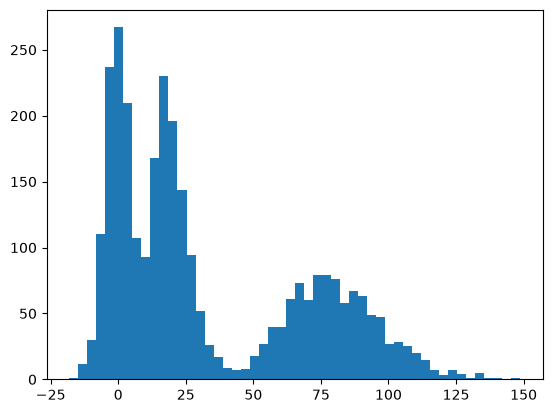

In [1]:
# Create a distribution that is the combination of three other distributions
from matplotlib import pyplot
from numpy.random import normal, gamma
from numpy import hstack
shape, scale = 10, 2.
s1 = gamma(shape, scale, 1000)
s2 = gamma(shape * 2, scale * 2, 1000)
s3 = normal(loc=0, scale=5, size=1000)
sample = hstack((s1, s2, s3))
# plot the histogram
pyplot.hist(sample, bins=50)
pyplot.show()

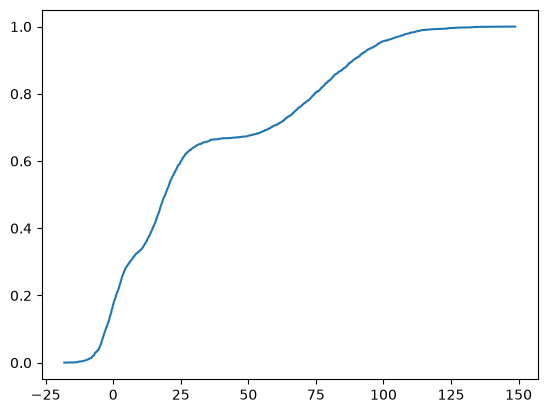

In [2]:
# fit a cdf
from statsmodels.distributions.empirical_distribution import ECDF
sample_ecdf = ECDF(sample)

# plot the cdf
pyplot.plot(sample_ecdf.x, sample_ecdf.y)
pyplot.show()

In [3]:
print('P(x<-20): %.4f' % sample_ecdf(-20))
print('P(x<-2): %.4f' % sample_ecdf(-2))
print('P(x<0): %.4f' % sample_ecdf(0))
print('P(x<25): %.4f' % sample_ecdf(25))
print('P(x<50): %.4f' % sample_ecdf(50))
print('P(x<75): %.4f' % sample_ecdf(75))
print('P(x<100): %.4f' % sample_ecdf(100))
print('P(x<125): %.4f' % sample_ecdf(125))
print('P(x<140): %.4f' % sample_ecdf(140))
print('P(x<150): %.4f' % sample_ecdf(150))

P(x<-20): 0.0000
P(x<-2): 0.1163
P(x<0): 0.1730
P(x<25): 0.5987
P(x<50): 0.6753
P(x<75): 0.8037
P(x<100): 0.9567
P(x<125): 0.9957
P(x<140): 0.9993
P(x<150): 1.0000


In [4]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# from matplotlib import pyplot as plt
import optuna
from sklearn.metrics import average_precision_score, confusion_matrix
import shap

from pyod.models.combination import aom, moa, average, maximization
from pyod.utils.utility import standardizer
from pyod.models.ecod import ECOD


from src.ML_Utils import (DGP, plot_generated_data, plot_hist, count_stat,
                          evaluate_model, descriptive_stat_threshold, confusion_matrix)

NETWORK_TRAFFIC_PATH = Path.cwd().parent / "data" / "network_traffic" 
NETWORK_TRAFFIC_TRAIN = NETWORK_TRAFFIC_PATH / "df_train.csv"
NETWORK_TRAFFIC_VALID = NETWORK_TRAFFIC_PATH / "df_valid.csv"
NETWORK_TRAFFIC_TEST = NETWORK_TRAFFIC_PATH / "df_hold.csv"

/Users/mayazwang/Files/00_Learning/_AI_security/Anomaly_detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load data

In [5]:
df_train = pd.read_csv(NETWORK_TRAFFIC_TRAIN)
X_train = df_train.drop("label", axis=1)
y_train = df_train['label']
# print(y_train)
X_train.head()

,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,frequency_band_energy,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.130995,0.325352,64796,80,0.714286,0.0,0.836820,0.621469,False,True,False,False,True,False,False,True,False
1,0.983536,0.341513,25476,443,0.357143,0.0,0.109997,0.462735,True,False,False,False,False,False,True,False,False
2,0.040086,0.812864,7022,80,0.071429,0.0,0.506324,0.734016,True,False,True,False,True,False,False,False,False
3,0.928418,0.725507,60573,80,0.000000,0.0,0.914045,0.923464,True,False,False,False,False,True,False,False,False
4,0.545455,0.323503,30487,53,0.571429,0.0,0.992607,0.590219,False,False,True,False,False,False,False,False,False


In [6]:
df_valid= pd.read_csv(NETWORK_TRAFFIC_VALID)
X_valid = df_valid.drop("label", axis=1)
y_valid = df_valid['label']

In [7]:
df_test= pd.read_csv(NETWORK_TRAFFIC_TEST)
X_test = df_test.drop("label", axis=1)
y_test = df_test['label']

### Step 1: Build the model

In [8]:
ecod = ECOD() #contamination=0.05)
ecod.fit(X_train)

,contamination,0.1
,n_jobs,1
Name,Type,Value
decision_scores_,"ndarray[float64](700,)","[17.31,15.98,17.02,...,12.82,15.73,19.19]"
labels_,"ndarray[int64](700,)","[0,0,0,...,0,0,0]"
threshold_,float64,19.19


In [12]:
results = evaluate_model(ecod, X_train, X_test)
y_train_scores = results["train_scores"]
y_train_pred = results["train_pred"]

y_test_scores = results["test_scores"]
y_test_pred = results["test_pred"]
threshold = results["threshold"]

In [11]:
# Threshold for the defined comtanimation rate
print("The threshold for the defined contamination rate:" , threshold)
print("The training data:", count_stat(y_train_pred))
print("The test data:", count_stat(y_test_pred))

The threshold for the defined contamination rate: 19.192268256590207
The training data: {0: 630, 1: 70}
The test data: {0: 127, 1: 23}


In [13]:
pick_outliers = np.where(y_train_scores>results["threshold"])
pick_outliers[0]

array([  3,  18,  49,  58,  70,  72,  73,  82,  84,  95, 103, 106, 117,
       128, 132, 138, 142, 157, 172, 178, 184, 200, 201, 217, 235, 242,
       243, 248, 260, 272, 281, 300, 304, 314, 339, 351, 357, 363, 366,
       377, 395, 405, 410, 414, 442, 444, 455, 463, 471, 474, 495, 519,
       528, 532, 537, 553, 556, 559, 565, 573, 581, 589, 593, 594, 609,
       620, 628, 632, 665, 667])

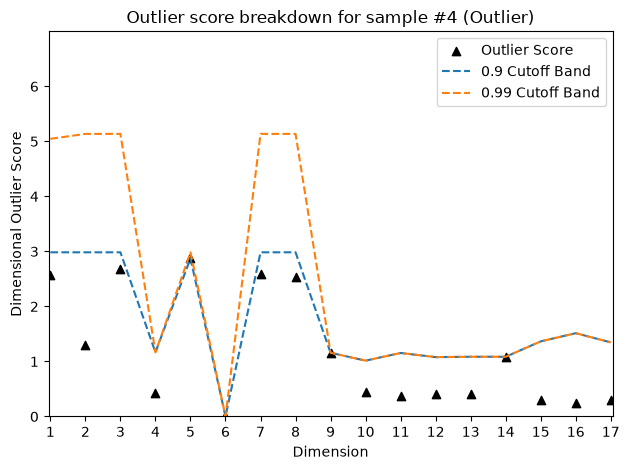

In [14]:
ecod.explain_outlier(pick_outliers[0][0])

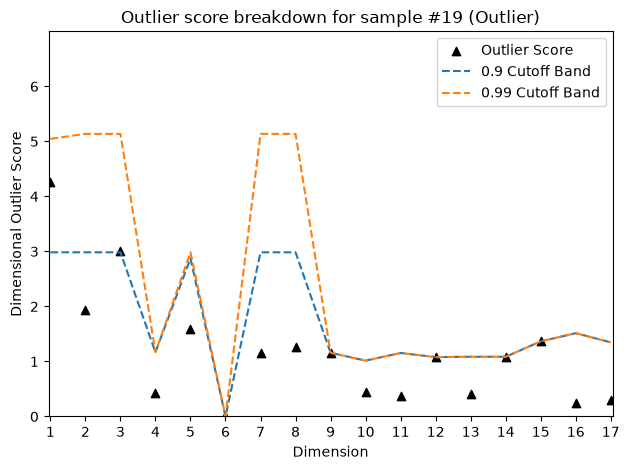

In [15]:
ecod.explain_outlier(pick_outliers[0][1])

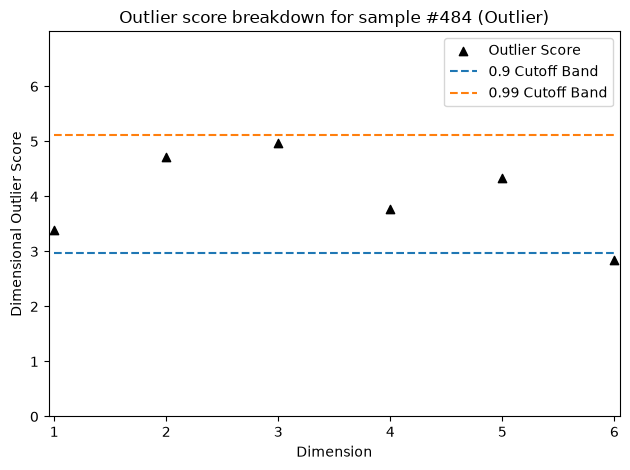

In [25]:
ecod.explain_outlier(pick_outliers[0][2])

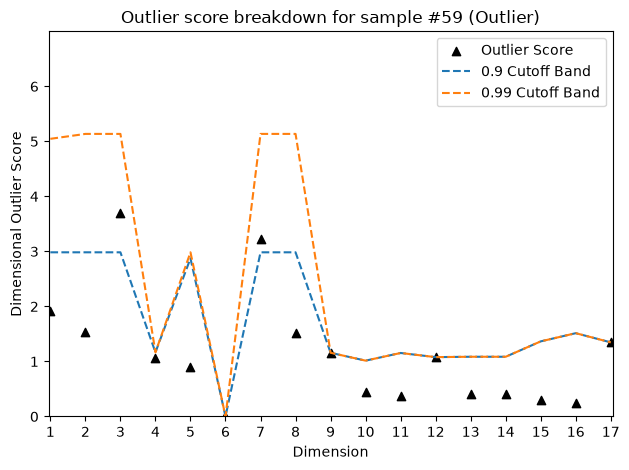

In [16]:
ecod.explain_outlier(pick_outliers[0][3])

### Step 2: Determine the threshold

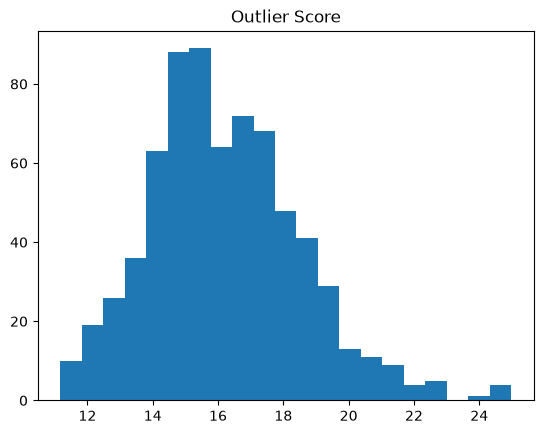

In [17]:
plot_hist(y_train_scores)

### Step 3: Descriptive statistics

In [19]:
descriptive_stat_threshold(X_train,y_train_scores, results['threshold'])

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,630,90.0,0.49,0.51,31947.08,200.56,0.50,0.0,0.49,...,0.31,0.35,0.33,0.32,0.33,0.33,0.25,0.22,0.26,15.71
1,Outlier,70,10.0,0.49,0.53,36152.89,162.54,0.55,0.0,0.45,...,0.40,0.37,0.34,0.41,0.40,0.37,0.31,0.24,0.23,20.73


In [22]:
pr_auc_score_train = average_precision_score(y_train,(y_train_scores>results['threshold']))
pr_auc_score_train

0.1

In [20]:
confusion_matrix(y_test,y_test_scores, results['threshold'])

Pred,0,1
Actual,,
0.0,115,20
1.0,12,3


In [23]:
pr_auc_score_test = average_precision_score(y_test,y_test_scores>results['threshold'])
pr_auc_score_test

0.10608695652173915

### Two models: HBOS and ECOD

In [24]:
########
# HBOS #
########
from pyod.models.hbos import HBOS
n_bins = 50
hbos = HBOS(n_bins=n_bins, contamination=0.1)
hbos.fit(X_train)

hbos_results = evaluate_model(hbos, X_train, X_test)
y_train_hbos_scores = hbos_results["train_scores"]
y_train_hbos_pred = hbos_results["train_pred"]

y_test_hbos_scores = hbos_results["test_scores"]
y_test_hbos_pred = hbos_results["test_pred"]
hbos_threshold = hbos_results["threshold"]

########
# ECOD #
########
from pyod.models.ecod import ECOD
clf_name = 'ECOD'
ecod = ECOD(contamination=0.1)
ecod.fit(X_train)

ecod_results = evaluate_model(ecod, X_train, X_test)
y_train_ecod_scores = ecod_results["train_scores"]
y_train_ecod_pred = ecod_results["train_pred"]

y_test_ecod_scores = ecod_results["test_scores"]
y_test_ecod_pred = ecod_results["test_pred"]
ecod_threshold = ecod_results["threshold"]

# Thresholds
[ecod_threshold, hbos_threshold]

[19.192268256590207, -33.933822711261136]

In [27]:
# Put the actual, the HBO score and the ECOD score together
Actual_pred = pd.DataFrame({'Actual': y_test, 'HBOS_pred': y_test_hbos_pred, 'ECOD_pred': y_test_ecod_pred})
Actual_pred.head()

,Actual,HBOS_pred,ECOD_pred
0,0.0,0,0
1,0.0,0,0
2,0.0,0,0
3,0.0,0,0
4,0.0,0,0


In [28]:

pd.crosstab(Actual_pred['Actual'],Actual_pred['ECOD_pred'])

ECOD_pred,0,1
Actual,,
0.0,115,20
1.0,12,3


In [29]:
pd.crosstab(Actual_pred['Actual'],Actual_pred['HBOS_pred'])

HBOS_pred,0,1
Actual,,
0.0,116,19
1.0,12,3


In [26]:
pd.crosstab(Actual_pred['HBOS_pred'],Actual_pred['ECOD_pred'])

ECOD_pred,0,1
HBOS_pred,,
0,110,18
1,17,5
